# Trayectoria de ángulos de los actuadores de las patas

Grafica, con `prettyPlot`, cada ángulo articular (hip, knee, ankle) de las 4 patas (fr, fl, br, bl) contenido en `leg_actuator_angles_trajectory_adapted.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from prettyPlot.plotting import pretty_labels

df = pd.read_csv("leg_actuator_angles_trajectory_adapted.csv")
time = df["time_s"]
angle_cols = [c for c in df.columns if c != "time_s"]
df.head()

,time_s,fr_hip_joint,fr_knee_joint,fr_ankle_joint,fl_hip_joint,fl_knee_joint,fl_ankle_joint,br_hip_joint,br_knee_joint,br_ankle_joint,bl_hip_joint,bl_knee_joint,bl_ankle_joint
0,0.000,40.825130,91.839325,140.84676,55.420933,126.351090,106.38661,-46.050540,-114.548874,-45.604220,-43.391018,-94.66641,-61.466324
1,0.005,40.712240,92.382200,142.51387,55.805590,126.823204,105.56879,-45.837860,-114.196600,-46.159462,-43.734830,-94.33500,-58.890053
2,0.010,40.587070,93.003784,143.92398,56.174800,127.297680,104.69525,-45.653084,-113.835230,-46.685270,-44.061005,-94.06254,-56.299305
3,0.015,40.448720,93.697320,145.07922,56.527184,127.768240,103.76399,-45.494740,-113.460915,-47.176815,-44.367332,-93.85924,-53.725178
4,0.020,40.297466,94.455315,145.98550,56.861595,128.227250,102.77416,-45.360990,-113.070540,-47.630898,-44.652410,-93.73466,-51.197746


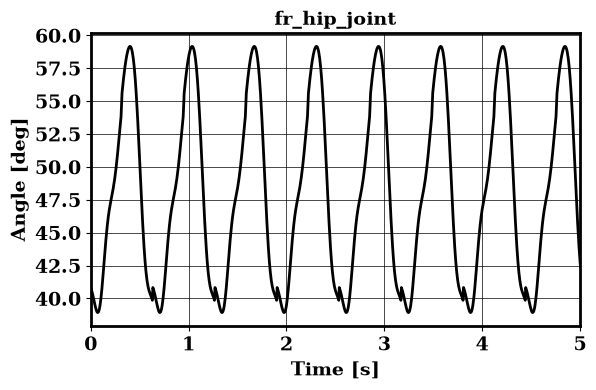

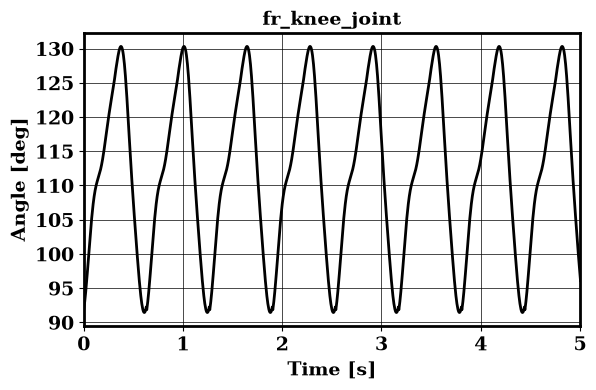

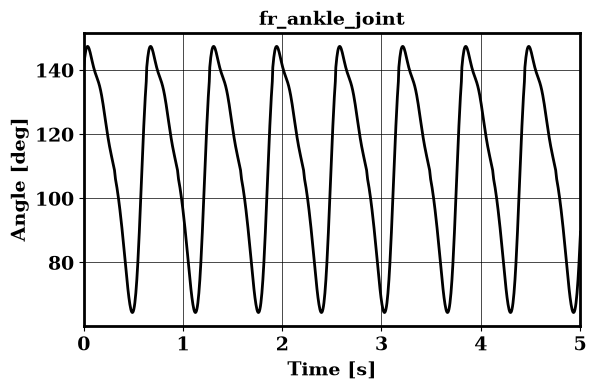

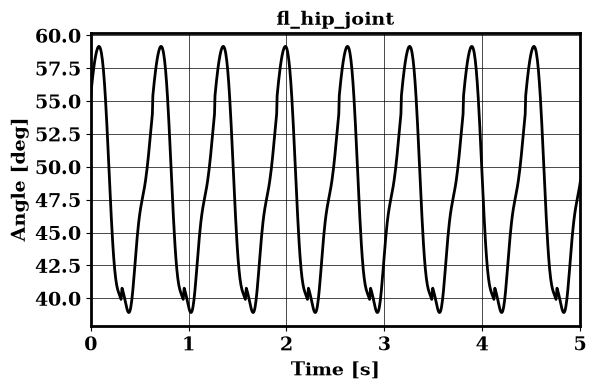

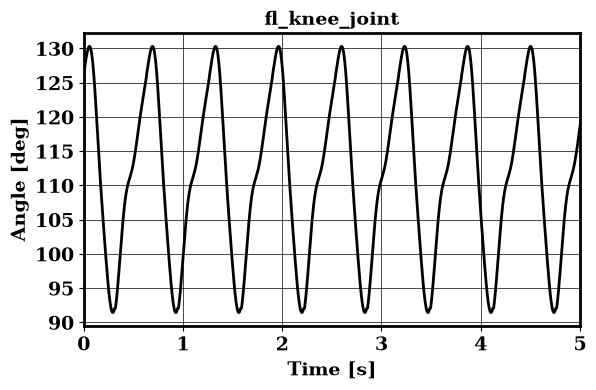

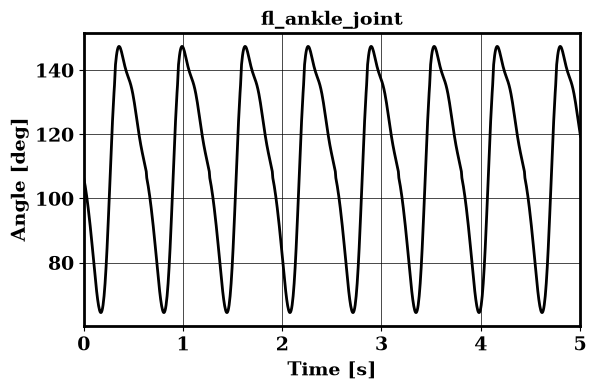

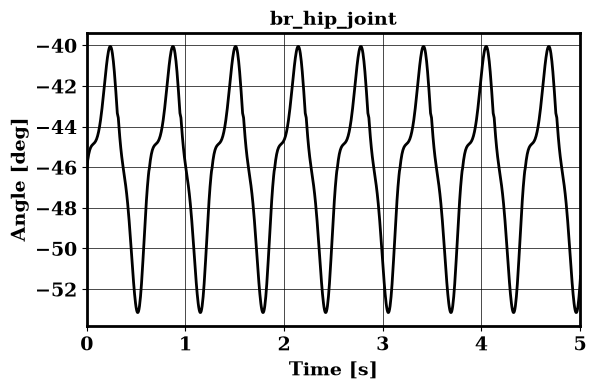

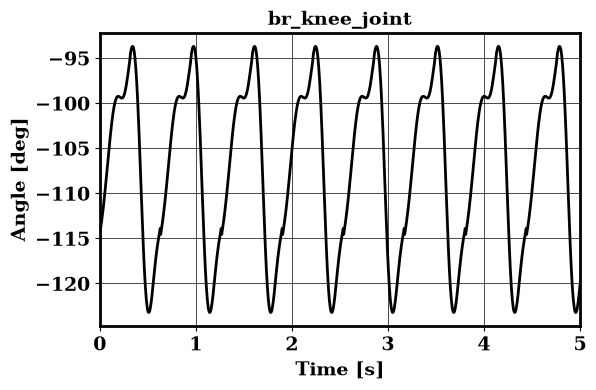

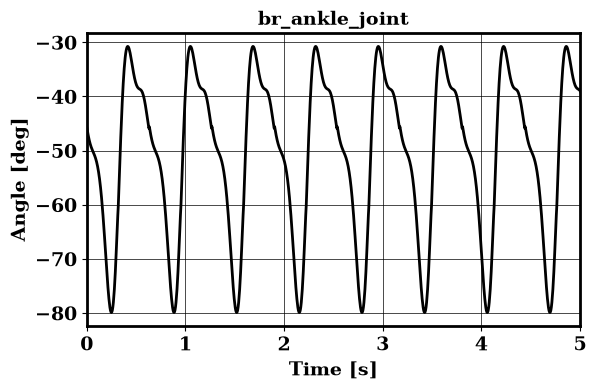

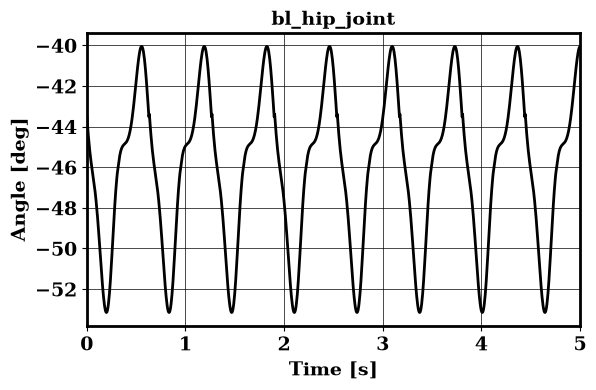

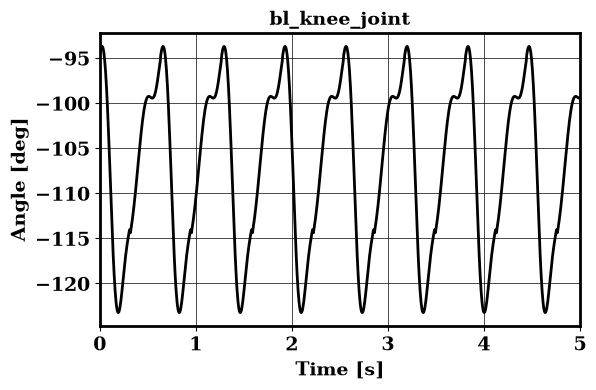

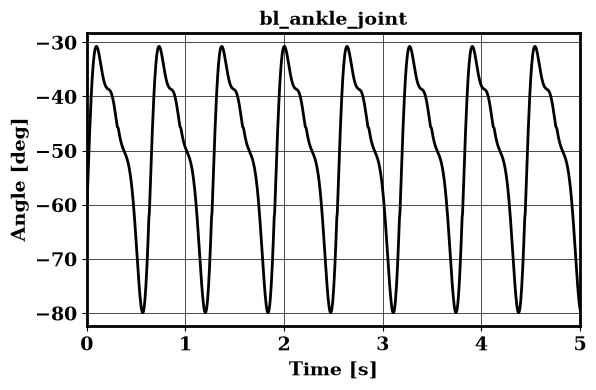

In [2]:
for col in angle_cols:
    fig = plt.figure(figsize=(6, 4))
    plt.plot(time, df[col], color="k", linewidth=2)
    pretty_labels("Time [s]", "Angle [deg]", title=col)
    plt.xlim(0, 5)
    plt.show()

## Vista combinada por pata

Un subplot por pata (fr, fl, br, bl) con sus 3 articulaciones superpuestas.

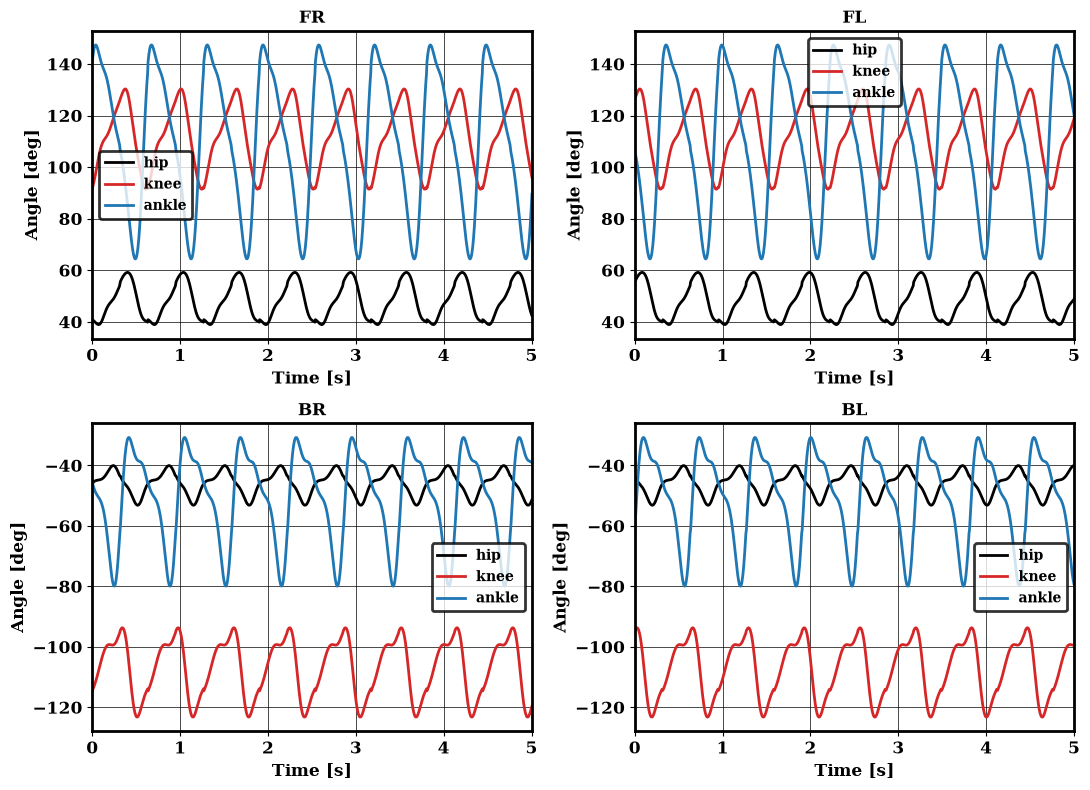

In [3]:
from prettyPlot.plotting import pretty_legend

legs = ["fr", "fl", "br", "bl"]
joints = ["hip_joint", "knee_joint", "ankle_joint"]
colors = {"hip_joint": "k", "knee_joint": "tab:red", "ankle_joint": "tab:blue"}

fig, axs = plt.subplots(2, 2, figsize=(11, 8))
for ax, leg in zip(axs.flat, legs):
    for joint in joints:
        ax.plot(
            time,
            df[f"{leg}_{joint}"],
            label=joint.replace("_joint", ""),
            color=colors[joint],
            linewidth=2,
        )
    pretty_labels("Time [s]", "Angle [deg]", title=leg.upper(), ax=ax, fontsize=12)
    pretty_legend(ax=ax, fontsize=10)
    ax.set_xlim(0, 5)
plt.show()

## Extraer un solo ciclo

El CSV completo resulta ser un *tiling* exacto de un mismo ciclo corto, repetido muchas veces (se verifica abajo: diferencia máxima = 0.0 entre repeticiones). Esta celda detecta el período exacto por autocorrelación y guarda un solo ciclo en `leg_actuator_angles_one_cycle.csv`.

In [4]:
import numpy as np
from scipy.signal import find_peaks

x = df["fr_hip_joint"].to_numpy()
n = len(x)
dt = df["time_s"].diff().median()
xm = x - x.mean()

# Autocorrelación (via FFT) para detectar el período del ciclo
f = np.fft.rfft(xm, n=2 * n)
acf = np.fft.irfft(f * np.conj(f))[:n]
acf /= acf[0]

peaks, _ = find_peaks(acf, height=0.5)
CYCLE_LEN = peaks[peaks > 5][0]  # primer pico significativo tras el lag 0
print(f"Período detectado: {CYCLE_LEN} muestras ({CYCLE_LEN * dt:.3f} s)")

# Verifica que el CSV completo sea un tiling exacto de ese período
cols = [c for c in df.columns if c != "time_s"]
X = df[cols].to_numpy()
max_diff = np.abs(X[: n - CYCLE_LEN] - X[CYCLE_LEN:]).max()
print(f"Diferencia máxima entre repeticiones del ciclo: {max_diff:.6f}")
print(f"n / CYCLE_LEN = {n / CYCLE_LEN}")

cycle = df.iloc[:CYCLE_LEN].reset_index(drop=True)
print(f"Un ciclo: {len(cycle)} muestras, t=0.000s a t={cycle['time_s'].iloc[-1]:.3f}s")

cycle.to_csv("leg_actuator_angles_one_cycle.csv", index=False)
cycle.head()

Período detectado: 127 muestras (0.635 s)
Diferencia máxima entre repeticiones del ciclo: 0.000000
n / CYCLE_LEN = 95.0
Un ciclo: 127 muestras, t=0.000s a t=0.630s


,time_s,fr_hip_joint,fr_knee_joint,fr_ankle_joint,fl_hip_joint,fl_knee_joint,fl_ankle_joint,br_hip_joint,br_knee_joint,br_ankle_joint,bl_hip_joint,bl_knee_joint,bl_ankle_joint
0,0.000,40.825130,91.839325,140.84676,55.420933,126.351090,106.38661,-46.050540,-114.548874,-45.604220,-43.391018,-94.66641,-61.466324
1,0.005,40.712240,92.382200,142.51387,55.805590,126.823204,105.56879,-45.837860,-114.196600,-46.159462,-43.734830,-94.33500,-58.890053
2,0.010,40.587070,93.003784,143.92398,56.174800,127.297680,104.69525,-45.653084,-113.835230,-46.685270,-44.061005,-94.06254,-56.299305
3,0.015,40.448720,93.697320,145.07922,56.527184,127.768240,103.76399,-45.494740,-113.460915,-47.176815,-44.367332,-93.85924,-53.725178
4,0.020,40.297466,94.455315,145.98550,56.861595,128.227250,102.77416,-45.360990,-113.070540,-47.630898,-44.652410,-93.73466,-51.197746


## Animación de la pata FR

Reconstruye la pata FR como una cadena de 3 segmentos (hip → knee → ankle) usando las longitudes de la tabla de especificaciones (columna "Front"):

| Segmento | Longitud [cm] |
|---|---|
| Hip (muslo) | 12.1 |
| Knee (espinilla) | 11.1 |
| Ankle (pie) | 15.3 |

**Convención de ángulos**: cada articulación usa la convención típica de servo hobby, donde **90° = continuación recta** del segmento anterior (igual que la posición neutra usada en el notebook de la ESP32). Es decir, el ángulo de knee/ankle es la rotación *relativa* respecto al segmento previo, centrada en 90°.

**Offset de base confirmado: -90°.** `BASE_ANGLE_OFFSET_DEG` rota rígidamente toda la pata alrededor del pivote de la cadera (solo la orientación *global* del primer segmento, no las rotaciones relativas entre segmentos). Se probó +90° (la pata quedaba apuntando hacia arriba, físicamente incorrecto) y -90°, confirmado como el correcto.

La animación cubre los primeros 5 segundos a ~20 fps (downsample del CSV, que viene a 200 Hz) y se muestra como HTML interactivo (`anim.to_jshtml`), con controles de play/pausa y un slider para recorrer el tiempo manualmente. El panel derecho muestra los ángulos relativos hip/knee/ankle vs. tiempo con un marcador sincronizado.

In [ ]:
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Longitudes de segmento de la pata FR (columna "Front" de la tabla), en cm
L_HIP, L_KNEE, L_ANKLE = 12.1, 11.1, 15.3

# Offset global de base: rota toda la pata (de forma rigida) alrededor del
# pivote de la cadera. Confirmado: -90 grados es el correcto.
BASE_ANGLE_OFFSET_DEG = -90

# Downsample a ~20 fps para una animación fluida y liviana (CSV viene a 200 Hz),
# y recorta a los primeros ANIM_DURATION_S segundos.
ANIM_FPS = 20
ANIM_DURATION_S = 5
dt_csv = df["time_s"].diff().median()
step = max(1, int(round((1 / ANIM_FPS) / dt_csv)))
anim_df = df[df["time_s"] <= ANIM_DURATION_S].iloc[::step].reset_index(drop=True)

hip = np.radians(anim_df["fr_hip_joint"].to_numpy())
knee = np.radians(anim_df["fr_knee_joint"].to_numpy())
ankle = np.radians(anim_df["fr_ankle_joint"].to_numpy())

# Cadena cinemática: 90 deg (entre segmentos) = continuacion recta del
# segmento anterior (misma convencion neutra que los servos: 90,90,90 =
# pata estirada). BASE_ANGLE_OFFSET_DEG rota el conjunto completo.
phi_hip = hip + np.radians(BASE_ANGLE_OFFSET_DEG)
phi_knee = phi_hip + knee - np.pi / 2
phi_ankle = phi_knee + ankle - np.pi / 2


def seg_dir(theta):
    return np.column_stack([np.sin(theta), -np.cos(theta)])


p0 = np.zeros((len(anim_df), 2))
p1 = p0 + L_HIP * seg_dir(phi_hip)
p2 = p1 + L_KNEE * seg_dir(phi_knee)
p3 = p2 + L_ANKLE * seg_dir(phi_ankle)

reach = L_HIP + L_KNEE + L_ANKLE

# Ángulos articulares "crudos" (relativos entre cuerpos consecutivos):
# hip_joint = ángulo cadera-muslo, knee_joint = muslo-espinilla, ankle_joint = espinilla-pie
joint_angle_deg = {
    "Hip": anim_df["fr_hip_joint"].to_numpy(),
    "Knee": anim_df["fr_knee_joint"].to_numpy(),
    "Ankle": anim_df["fr_ankle_joint"].to_numpy(),
}
joint_colors = {"Hip": "tab:blue", "Knee": "tab:red", "Ankle": "tab:green"}
t_anim = anim_df["time_s"].to_numpy()

fig, (ax, ax_ang) = plt.subplots(1, 2, figsize=(11, 5))

# --- Panel izquierdo: cadena cinemática de la pata ---
ax.set_xlim(-reach * 1.3, reach * 1.3)
ax.set_ylim(-reach * 1.3, reach * 1.3)
ax.set_aspect("equal")
pretty_labels("x [cm]", "y [cm]", title=f"Pata FR (offset base {BASE_ANGLE_OFFSET_DEG}°)", ax=ax)

(line,) = ax.plot([], [], "o-", color="k", linewidth=3, markersize=8)
time_text = ax.text(0.03, 0.97, "", transform=ax.transAxes, fontsize=11, fontweight="bold", va="top")

# Etiquetas de ángulo relativo junto a cada articulación (knee y ankle)
knee_angle_text = ax.text(0, 0, "", fontsize=9, color=joint_colors["Knee"], fontweight="bold")
ankle_angle_text = ax.text(0, 0, "", fontsize=9, color=joint_colors["Ankle"], fontweight="bold")

# --- Panel derecho: ángulos articulares (relativos) vs tiempo ---
for name, values in joint_angle_deg.items():
    ax_ang.plot(t_anim, values, color=joint_colors[name], linewidth=2, label=name)
pretty_labels("Time [s]", "Angle [deg]", title="Ángulos relativos (hip/knee/ankle)", ax=ax_ang, fontsize=11)
pretty_legend(ax=ax_ang, fontsize=9)
ax_ang.set_xlim(t_anim[0], t_anim[-1])

vline = ax_ang.axvline(t_anim[0], color="gray", linestyle="--", linewidth=1.5)
dots = {
    name: ax_ang.plot([], [], "o", color=joint_colors[name], markersize=8)[0]
    for name in joint_angle_deg
}


def update(i):
    xs = [p0[i, 0], p1[i, 0], p2[i, 0], p3[i, 0]]
    ys = [p0[i, 1], p1[i, 1], p2[i, 1], p3[i, 1]]
    line.set_data(xs, ys)
    time_text.set_text(f"t = {anim_df['time_s'].iloc[i]:.2f} s")

    knee_angle_text.set_position((p1[i, 0], p1[i, 1]))
    knee_angle_text.set_text(f"{anim_df['fr_knee_joint'].iloc[i]:.0f}°")
    ankle_angle_text.set_position((p2[i, 0], p2[i, 1]))
    ankle_angle_text.set_text(f"{anim_df['fr_ankle_joint'].iloc[i]:.0f}°")

    vline.set_xdata([t_anim[i], t_anim[i]])
    for name, dot in dots.items():
        dot.set_data([t_anim[i]], [joint_angle_deg[name][i]])

    return (line, time_text, knee_angle_text, ankle_angle_text, vline, *dots.values())


anim = FuncAnimation(fig, update, frames=len(anim_df), interval=1000 / ANIM_FPS, blit=True)

# Display como HTML interactivo (controles play/pausa/slider para recorrer el tiempo)
# en vez de GIF estático.
html_anim = HTML(anim.to_jshtml(fps=ANIM_FPS))
plt.close(fig)
html_anim

## Imagen de la posición inicial

Pose estática de la pata FR en `t=0` (mismas longitudes de segmento y convención de ángulos que la animación de arriba, offset de base -90° ya aplicado). Útil como referencia visual rápida, por ejemplo para armar el mecanismo.

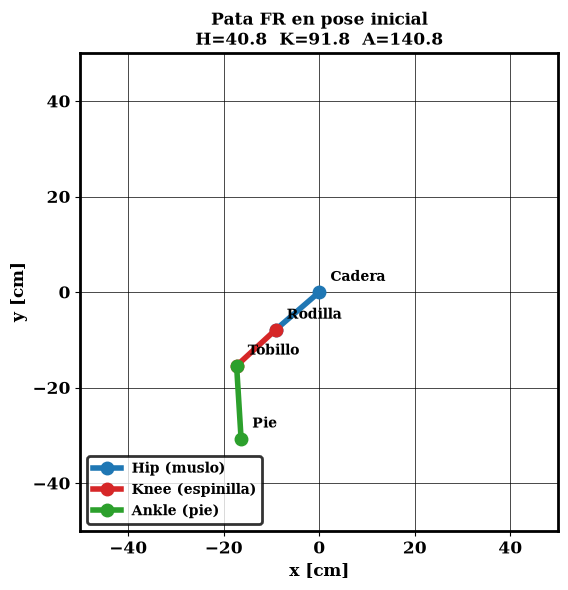

In [ ]:
initial_hip = float(df["fr_hip_joint"].iloc[0])
initial_knee = float(df["fr_knee_joint"].iloc[0])
initial_ankle = float(df["fr_ankle_joint"].iloc[0])

hip_r = np.radians(initial_hip)
knee_r = np.radians(initial_knee)
ankle_r = np.radians(initial_ankle)

phi_hip0 = hip_r + np.radians(BASE_ANGLE_OFFSET_DEG)
phi_knee0 = phi_hip0 + knee_r - np.pi / 2
phi_ankle0 = phi_knee0 + ankle_r - np.pi / 2


def seg_dir_scalar(theta):
    return np.array([np.sin(theta), -np.cos(theta)])


q0 = np.zeros(2)
q1 = q0 + L_HIP * seg_dir_scalar(phi_hip0)
q2 = q1 + L_KNEE * seg_dir_scalar(phi_knee0)
q3 = q2 + L_ANKLE * seg_dir_scalar(phi_ankle0)

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-reach * 1.3, reach * 1.3)
ax.set_ylim(-reach * 1.3, reach * 1.3)
ax.set_aspect("equal")

segments = [
    (q0, q1, "Hip (muslo)", "tab:blue"),
    (q1, q2, "Knee (espinilla)", "tab:red"),
    (q2, q3, "Ankle (pie)", "tab:green"),
]
for start, end, label, color in segments:
    ax.plot([start[0], end[0]], [start[1], end[1]], "o-", color=color, linewidth=4, markersize=9, label=label)

joints = [(q0, "Cadera"), (q1, "Rodilla"), (q2, "Tobillo"), (q3, "Pie")]
for point, name in joints:
    ax.annotate(
        name,
        point,
        textcoords="offset points",
        xytext=(8, 8),
        fontsize=10,
        fontweight="bold",
        fontname="serif",
    )

pretty_labels(
    "x [cm]",
    "y [cm]",
    title=f"Pata FR en pose inicial\nH={initial_hip:.1f}  K={initial_knee:.1f}  A={initial_ankle:.1f}",
    fontsize=12,
    ax=ax,
)
pretty_legend(ax=ax, fontsize=10, loc="lower left")
fig.savefig("fr_leg_initial_pose.png", dpi=150)
plt.show()

## Explorador interactivo de ángulos

Abre una **ventana emergente** (backend `Tk`, fuera del notebook) con sliders nativos de matplotlib para `hip`, `knee` y `ankle` (convención de servo, 90° = recto) que mueven la pata FR en tiempo real. El panel derecho de esa misma ventana refleja, como barras, los tres ángulos relativos actuales.

Requiere kernel activo. Al ejecutar la celda se abre la ventana; ciérrala para volver al backend inline si vas a seguir graficando en el notebook.

In [ ]:
get_ipython().run_line_magic("matplotlib", "tk")

from matplotlib.widgets import Slider

joint_names = ["Hip", "Knee", "Ankle"]
joint_colors_i = {"Hip": "tab:blue", "Knee": "tab:red", "Ankle": "tab:green"}


def leg_points(hip_deg, knee_deg, ankle_deg):
    phi_hip = np.radians(hip_deg) + np.radians(BASE_ANGLE_OFFSET_DEG)
    phi_knee = phi_hip + np.radians(knee_deg) - np.pi / 2
    phi_ankle = phi_knee + np.radians(ankle_deg) - np.pi / 2
    pt0 = np.zeros(2)
    pt1 = pt0 + L_HIP * seg_dir_scalar(phi_hip)
    pt2 = pt1 + L_KNEE * seg_dir_scalar(phi_knee)
    pt3 = pt2 + L_ANKLE * seg_dir_scalar(phi_ankle)
    return pt0, pt1, pt2, pt3


fig_i = plt.figure(figsize=(10, 6))
fig_i.canvas.manager.set_window_title("Pata FR - explorador interactivo")
ax_leg_i = fig_i.add_axes([0.06, 0.28, 0.42, 0.66])
ax_bar_i = fig_i.add_axes([0.56, 0.28, 0.40, 0.66])

ax_hip = fig_i.add_axes([0.15, 0.16, 0.7, 0.03])
ax_knee = fig_i.add_axes([0.15, 0.10, 0.7, 0.03])
ax_ankle = fig_i.add_axes([0.15, 0.04, 0.7, 0.03])

hip_slider = Slider(ax_hip, "Hip [°]", 0, 180, valinit=initial_hip, color=joint_colors_i["Hip"])
knee_slider = Slider(ax_knee, "Knee [°]", 0, 180, valinit=initial_knee, color=joint_colors_i["Knee"])
ankle_slider = Slider(ax_ankle, "Ankle [°]", 0, 180, valinit=initial_ankle, color=joint_colors_i["Ankle"])


def redraw(_event=None):
    hip_deg, knee_deg, ankle_deg = hip_slider.val, knee_slider.val, ankle_slider.val
    pt0, pt1, pt2, pt3 = leg_points(hip_deg, knee_deg, ankle_deg)

    ax_leg_i.clear()
    segments = [
        (pt0, pt1, "Hip", joint_colors_i["Hip"]),
        (pt1, pt2, "Knee", joint_colors_i["Knee"]),
        (pt2, pt3, "Ankle", joint_colors_i["Ankle"]),
    ]
    for start, end, label, color in segments:
        ax_leg_i.plot([start[0], end[0]], [start[1], end[1]], "o-", color=color, linewidth=4, markersize=9, label=label)
    ax_leg_i.set_xlim(-reach * 1.3, reach * 1.3)
    ax_leg_i.set_ylim(-reach * 1.3, reach * 1.3)
    ax_leg_i.set_aspect("equal")
    pretty_labels("x [cm]", "y [cm]", title="Pata FR (interactiva)", ax=ax_leg_i, fontsize=11)
    pretty_legend(ax=ax_leg_i, fontsize=9, loc="lower left")

    ax_bar_i.clear()
    values = [hip_deg, knee_deg, ankle_deg]
    bars = ax_bar_i.bar(joint_names, values, color=[joint_colors_i[n] for n in joint_names])
    ax_bar_i.axhline(90, color="gray", linestyle="--", linewidth=1, label="90° (recto)")
    ax_bar_i.set_ylim(0, 180)
    for bar, val in zip(bars, values):
        ax_bar_i.text(bar.get_x() + bar.get_width() / 2, val + 3, f"{val:.0f}°", ha="center", fontsize=10, fontweight="bold")
    pretty_labels("Articulación", "Angle [deg]", title="Ángulos relativos actuales", ax=ax_bar_i, fontsize=11)
    pretty_legend(ax=ax_bar_i, fontsize=9, loc="upper right")

    fig_i.canvas.draw_idle()


hip_slider.on_changed(redraw)
knee_slider.on_changed(redraw)
ankle_slider.on_changed(redraw)

redraw()
plt.show()

c:\Users\andre\OneDrive\Documents\Tesis\Python\tesis\Lib\site-packages\prettyPlot\plotting.py:116: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
